# 01 - Flood mapping with Sentinel-1 SAR: Storm Daniel, Thessaly (September 2023)

Storm Daniel brought extreme rainfall to central Greece on 4-7 September 2023 and flooded large parts of the Thessaly plain.
This notebook maps the flood extent with **Sentinel-1 SAR**, which sees through clouds, using a **change-detection** approach:

1. Sentinel-1 images **before** and **after** the event, from the **same orbit**
2. Speckle reduction
3. Backscatter change (after - before, in dB)
4. Flood = strong decrease in backscatter **and** low backscatter after the event
5. Removal of permanent water, steep slopes and isolated pixels
6. Flooded area in km²

> **How this notebook relates to `src/flood.py`.** Here the method is built step by step on a single Sentinel-1 pass, so that every stage can be seen and checked (images, histograms, thresholds). The same method, as reusable functions, lives in `src/flood.py`; notebooks 02–05 use only those functions. The last cell of this notebook uses them too, to map both passes at the peak of the flood.

In [1]:
import ee
import geemap

# First time only: opens a browser window to log in with your Google account
# ee.Authenticate()   # already done from the terminal

from pathlib import Path
# Your Earth Engine project id lives in project_id.txt (project root, not uploaded to GitHub)
_pid_file = Path.cwd().parent / "project_id.txt"
PROJECT_ID = _pid_file.read_text().strip() if _pid_file.exists() else "your-gcp-project-id"
ee.Initialize(project=PROJECT_ID)

## 1. Area of interest and dates

In [2]:
# Thessaly plain: Larissa, Karditsa, Trikala and the Karla basin
aoi = ee.Geometry.Rectangle([21.60, 39.20, 22.90, 39.85])

# Before: late August - 3 September 2023 | After: a few days after the peak
PRE_START, PRE_END = "2023-08-15", "2023-09-04"
#POST_START, POST_END = "2023-09-06", "2023-09-13"
POST_START, POST_END = "2023-09-12", "2023-09-13"


## 2. Sentinel-1 collection

In [3]:
s1 = (ee.ImageCollection("COPERNICUS/S1_GRD")
      .filterBounds(aoi)
      .filter(ee.Filter.eq("instrumentMode", "IW"))
      .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
      .select("VV"))

post_col = s1.filterDate(POST_START, POST_END)

# Use the same relative orbit before and after, so that the viewing geometry is identical
orbit = post_col.first().get("relativeOrbitNumber_start")
post_col = post_col.filter(ee.Filter.eq("relativeOrbitNumber_start", orbit))
pre_col = s1.filterDate(PRE_START, PRE_END).filter(ee.Filter.eq("relativeOrbitNumber_start", orbit))

print("Relative orbit:", orbit.getInfo())
print("Images before:", pre_col.size().getInfo())
print("Dates before: ", pre_col.aggregate_array("system:time_start")
      .map(lambda t: ee.Date(t).format("YYYY-MM-dd")).getInfo())
print("Images after: ", post_col.size().getInfo())
print("Dates after:  ", post_col.aggregate_array("system:time_start")
      .map(lambda t: ee.Date(t).format("YYYY-MM-dd")).getInfo())

Relative orbit: 175
Images before: 4
Dates before:  ['2023-08-19', '2023-08-19', '2023-08-31', '2023-08-31']
Images after:  2
Dates after:   ['2023-09-12', '2023-09-12']


In [4]:
# All Sentinel-1 acquisitions over the AOI, 1-20 September 2023
sept = s1.filterDate("2023-09-01", "2023-09-21")

info = sept.map(lambda img: ee.Feature(None, {
    "date": img.date().format("YYYY-MM-dd HH:mm"),
    "orbit": img.get("relativeOrbitNumber_start"),
    "pass": img.get("orbitProperties_pass"),
    "coverage_%": img.geometry().intersection(aoi, 1).area(1)
                    .divide(aoi.area(1)).multiply(100).round()
}))

import pandas as pd
df = pd.DataFrame([f["properties"] for f in info.getInfo()["features"]])
df.sort_values("date")

,coverage_%,date,orbit,pass
0,12,2023-09-01 04:31,7,DESCENDING
1,70,2023-09-01 04:31,7,DESCENDING
2,56,2023-09-06 04:39,80,DESCENDING
3,34,2023-09-06 04:40,80,DESCENDING
4,39,2023-09-07 16:24,102,ASCENDING
5,48,2023-09-07 16:24,102,ASCENDING
6,56,2023-09-12 16:32,175,ASCENDING
7,28,2023-09-12 16:32,175,ASCENDING
8,12,2023-09-13 04:31,7,DESCENDING
9,70,2023-09-13 04:31,7,DESCENDING


## 3. Composites and speckle reduction

SAR images contain *speckle* (granular noise). A focal median filter (50 m radius) smooths it while keeping edges.

In [5]:
SMOOTH_RADIUS = 50  # meters

pre = pre_col.median().clip(aoi).focalMedian(SMOOTH_RADIUS, "circle", "meters")
post = post_col.mosaic().clip(aoi).focalMedian(SMOOTH_RADIUS, "circle", "meters")

# Change in backscatter (dB): water is a smooth surface and appears dark in SAR
diff = post.subtract(pre).rename("diff")

## 4. Flood detection

A pixel is classified as flooded when backscatter **dropped by more than 3 dB** and is **below -15 dB** after the event.
These are common starting values; we check them with histograms right below, and against Copernicus EMS in notebook 02.

In [6]:
DIFF_THRESHOLD = -3    # dB
POST_THRESHOLD = -15   # dB

flood_raw = diff.lt(DIFF_THRESHOLD).And(post.lt(POST_THRESHOLD))

# Permanent water (present > 80% of the time, JRC Global Surface Water) is not flood
permanent_water = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence").gt(80)

# Floods do not stay on steep slopes
dem = ee.Image("USGS/SRTMGL1_003")
slope = ee.Terrain.slope(dem)

flood = (flood_raw
         .updateMask(permanent_water.unmask(0).Not())
         .updateMask(slope.lt(5)))

# Remove isolated groups of fewer than 8 connected pixels (noise)
connections = flood.selfMask().connectedPixelCount(25)
flood = flood.updateMask(connections.gte(8)).selfMask().rename("flood")

### Do the thresholds make sense? Look at the data

If water is much darker than land, the histogram of the "after" image should show a separate group of dark pixels, and the threshold should fall in the gap between the groups.
The last panel compares pixels we called flooded with pixels we did not (equal numbers of each, so the small flooded group is visible).
Otsu's method finds the threshold that best separates two groups of values: it is a sanity check, not a truth.

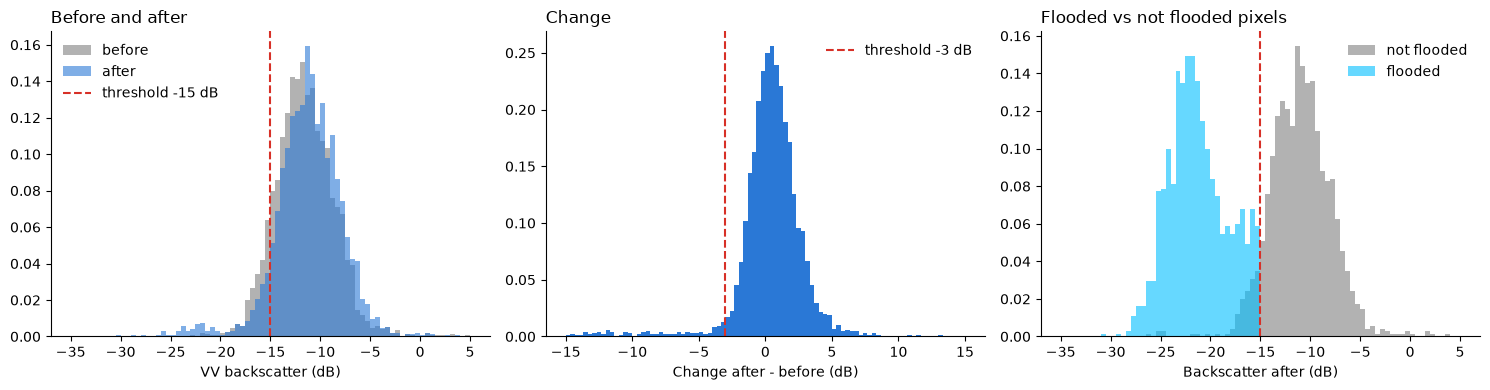

Pixels sampled: 3326
Share darker than -15 dB:  before 10.6%  |  after 8.7%
Otsu threshold on the 'after' image: -11.5 dB (we use -15 dB)
Otsu threshold on the change:        -5.0 dB (we use -3 dB)


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

layers = ee.Image.cat([pre.rename("pre"), post.rename("post"), diff,
                       flood.unmask(0).toInt().rename("flood")])

# Random sample (pixels outside the image footprint are dropped automatically)
rand = layers.sample(region=aoi, scale=30, numPixels=4000, seed=42)
rdf = pd.DataFrame([f["properties"] for f in rand.getInfo()["features"]]).dropna()

# Same number of flooded and non-flooded pixels
strat = layers.stratifiedSample(numPoints=1500, classBand="flood", region=aoi, scale=30, seed=42)
sdf = pd.DataFrame([f["properties"] for f in strat.getInfo()["features"]]).dropna()

def otsu(values, bins=256):
    hist, edges = np.histogram(values, bins=bins)
    centers = (edges[:-1] + edges[1:]) / 2
    w0 = np.cumsum(hist); w1 = w0[-1] - w0
    s0 = np.cumsum(hist * centers)
    m0 = s0 / np.maximum(w0, 1)
    m1 = (s0[-1] - s0) / np.maximum(w1, 1)
    return centers[np.argmax(w0 * w1 * (m0 - m1) ** 2)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
bins = np.linspace(-35, 5, 81)

ax = axes[0]
ax.hist(rdf["pre"], bins=bins, alpha=0.6, density=True, label="before", color="#7f7f7f")
ax.hist(rdf["post"], bins=bins, alpha=0.6, density=True, label="after", color="#2a78d6")
ax.axvline(POST_THRESHOLD, color="#d73027", ls="--", label=f"threshold {POST_THRESHOLD} dB")
ax.set_xlabel("VV backscatter (dB)"); ax.set_title("Before and after", loc="left"); ax.legend(frameon=False)

ax = axes[1]
ax.hist(rdf["diff"], bins=np.linspace(-15, 15, 91), density=True, color="#2a78d6")
ax.axvline(DIFF_THRESHOLD, color="#d73027", ls="--", label=f"threshold {DIFF_THRESHOLD} dB")
ax.set_xlabel("Change after - before (dB)"); ax.set_title("Change", loc="left"); ax.legend(frameon=False)

ax = axes[2]
ax.hist(sdf.loc[sdf.flood == 0, "post"], bins=bins, alpha=0.6, density=True, label="not flooded", color="#7f7f7f")
ax.hist(sdf.loc[sdf.flood == 1, "post"], bins=bins, alpha=0.6, density=True, label="flooded", color="#00bfff")
ax.axvline(POST_THRESHOLD, color="#d73027", ls="--")
ax.set_xlabel("Backscatter after (dB)"); ax.set_title("Flooded vs not flooded pixels", loc="left"); ax.legend(frameon=False)

for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

print(f"Pixels sampled: {len(rdf)}")
print(f"Share darker than {POST_THRESHOLD} dB:  before {np.mean(rdf['pre'] < POST_THRESHOLD):.1%}  |  after {np.mean(rdf['post'] < POST_THRESHOLD):.1%}")
print(f"Otsu threshold on the 'after' image: {otsu(rdf['post']):.1f} dB (we use {POST_THRESHOLD} dB)")
print(f"Otsu threshold on the change:        {otsu(rdf['diff']):.1f} dB (we use {DIFF_THRESHOLD} dB)")

## 5. Flooded area

In [8]:
area_m2 = (flood.multiply(ee.Image.pixelArea())
           .reduceRegion(reducer=ee.Reducer.sum(), geometry=aoi,
                         scale=10, maxPixels=1e10, bestEffort=True)
           .get("flood"))

area_km2 = ee.Number(area_m2).divide(1e6).getInfo()
print(f"Flooded area: {area_km2:,.1f} km²")

Flooded area: 238.0 km²


## 6. Map

In [9]:
m = geemap.Map(center=[39.55, 22.25], zoom=9)
m.add_basemap("SATELLITE")
m.addLayer(pre, {"min": -25, "max": 0}, "Sentinel-1 before (VV, dB)", False)
m.addLayer(post, {"min": -25, "max": 0}, "Sentinel-1 after (VV, dB)", False)
m.addLayer(diff, {"min": -8, "max": 8, "palette": ["#b2182b", "#f7f7f7", "#2166ac"]}, "Change (dB)", False)
m.addLayer(permanent_water.selfMask(), {"palette": ["#08306b"]}, "Permanent water")
m.addLayer(flood, {"palette": ["#00bfff"]}, "Flood extent")
m

Map(center=[39.55, 22.25], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

In [10]:
# The same method, wrapped in functions, lives in src/flood.py and is reused by notebooks 02-05.
# Here we use it to map both passes at the peak of the flood.
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))
from src.flood import flood_map, peak_flood, area_km2

flood_12, cov_12 = flood_map(aoi, "2023-09-12", "2023-09-13")   # orbit 175, ascending
flood_13, cov_13 = flood_map(aoi, "2023-09-13", "2023-09-14")   # orbit 7, descending

# A pixel is flooded if it is flooded in at least one of the two passes
flood_peak, coverage = peak_flood(aoi)

print(f"12/9 only:           {area_km2(flood_12, aoi):7.1f} km²")
print(f"13/9 only:           {area_km2(flood_13, aoi):7.1f} km²")
print(f"Combined (12+13/9):  {area_km2(flood_peak, aoi):7.1f} km²")
print(f"AOI covered:         {area_km2(coverage, aoi) / area_km2(ee.Image(1), aoi) * 100:5.1f} %")

# Sentinel-1 images of the two passes (same orbit selection as flood_map)
from src.flood import s1_vv

def s1_pass(d0, d1):
    col = s1_vv(aoi).filterDate(d0, d1)
    orbit = col.first().get("relativeOrbitNumber_start")
    return col.filter(ee.Filter.eq("relativeOrbitNumber_start", orbit)).mosaic().clip(aoi)

s1_12 = s1_pass("2023-09-12", "2023-09-13")
s1_13 = s1_pass("2023-09-13", "2023-09-14")
VV = {"min": -25, "max": 0}

m2 = geemap.Map(center=[39.55, 22.25], zoom=9)
m2.add_basemap("SATELLITE")
# Sentinel-1 backscatter (VV, dB) and the footprint of each pass: off by default, switch them on in the layer control
m2.addLayer(s1_12, VV, "Sentinel-1 12/9 (orbit 175, VV dB)", False)
m2.addLayer(s1_13, VV, "Sentinel-1 13/9 (orbit 7, VV dB)", False)
m2.addLayer(cov_12.selfMask(), {"palette": ["#ff8c00"], "opacity": 0.35}, "Footprint 12/9 (orbit 175)", False)
m2.addLayer(cov_13.selfMask(), {"palette": ["#ff00ff"], "opacity": 0.35}, "Footprint 13/9 (orbit 7)", False)
# Flood masks
m2.addLayer(flood_12.selfMask(), {"palette": ["#ff8c00"]}, "Flood 12/9 (orbit 175)", False)
m2.addLayer(flood_13.selfMask(), {"palette": ["#ff00ff"]}, "Flood 13/9 (orbit 7)", False)
m2.addLayer(flood_peak.selfMask(), {"palette": ["#00bfff"]}, "Flood peak (combined)")
m2

12/9 only:             238.0 km²
13/9 only:             294.8 km²
Combined (12+13/9):    342.1 km²
AOI covered:         100.0 %


Map(center=[39.55, 22.25], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…